In [16]:
from pprint import pprint

import numpy as np
import torch
from torch.utils.data import DataLoader

from src.config import DataConfig, TrainConfig, TransformConfig
from src.constants import FINAL_CLASSES
from src.features.dataframe import create_dataframe
from src.features.dataset import BloodCellDataset
from src.tasks import get_task
from src.training.components import build_sampler, build_transform

In [17]:
task = get_task("type")
data_config = DataConfig()
transform_config = TransformConfig()
df = create_dataframe(data_cfg=data_config, task=task)
tf = build_transform(transform_config, training=False)
ds = BloodCellDataset(df, task, tf)


ValueError: norm_stats='dataset' exige dataset_mean et dataset_std (passer les stats du split, ou utiliser norm_stats='imagenet').

## Déséquilibre de classe

Deux métriques pour qualifier le déséquilibre des classes dans `df` :
- **imbalance ratio** : effectif de la classe majoritaire / effectif de la classe minoritaire (simple, mais ignore la forme de la distribution entre les deux extrêmes).
- **entropie de Shannon normalisée** : capture le déséquilibre sur l'ensemble de la distribution (1 = parfaitement équilibré, 0 = très déséquilibré, une seule classe).

In [ ]:
class_counts = df[task.label_column].value_counts().sort_index()
display(class_counts)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Imbalance ratio (majoritaire/minoritaire) : {imbalance_ratio:.2f}")

proportions = class_counts / class_counts.sum()
shannon_entropy = -(proportions * np.log(proportions)).sum()
normalized_entropy = shannon_entropy / np.log(task.num_classes)
print(
    f"Entropie de Shannon normalisée : {normalized_entropy:.3f} (1 = équilibré, 0 = très déséquilibré)"
)

label
0.0     1297
1.0     3294
2.0     3541
3.0     1629
4.0     2360
5.0     5162
6.0     3209
7.0    11922
8.0     2348
9.0      680
Name: count, dtype: int64

Imbalance ratio (majoritaire/minoritaire) : 17.53
Entropie de Shannon normalisée : 0.875 (1 = équilibré, 0 = très déséquilibré)


In [ ]:
@torch.no_grad()
def count_labels(alpha):
    labels = df[task.label_column].to_numpy().astype(int)
    train_config = TrainConfig(sampler="weight", sampler_alpha=alpha, device="cpu")
    sampler = build_sampler(train_config, labels, task.num_classes)
    idx = torch.tensor(list(sampler))
    return torch.bincount(torch.from_numpy(labels)[idx], minlength=task.num_classes)


def imbalance_ratio(counts):
    return counts.max() / counts.min()


def shannon_entropy(counts):
    proportions = counts / counts.sum()
    shannon_entropy = -(proportions * np.log(proportions)).sum()
    return shannon_entropy / np.log(task.num_classes)


results = {}
for alpha in (0.0, 0.25, 0.5, 0.75, 1.0):
    counts = count_labels(alpha)
    results[str(alpha)] = {}
    results[str(alpha)]["imbalance_ratio"] = imbalance_ratio(counts)
    results[str(alpha)]["shannon_entropy"] = shannon_entropy(counts)
    # results[str(alpha)]["counts"] = dict(zip(FINAL_CLASSES, counts))

pprint(results)


{'0.0': {'imbalance_ratio': tensor(18.9968), 'shannon_entropy': tensor(0.8732)},
 '0.25': {'imbalance_ratio': tensor(8.6992), 'shannon_entropy': tensor(0.9289)},
 '0.5': {'imbalance_ratio': tensor(4.0495), 'shannon_entropy': tensor(0.9701)},
 '0.75': {'imbalance_ratio': tensor(2.0755), 'shannon_entropy': tensor(0.9917)},
 '1.0': {'imbalance_ratio': tensor(1.0589), 'shannon_entropy': tensor(0.9999)}}


/var/folders/m_/b04ywwq12g933cgpc9bdd6jm0000gn/T/ipykernel_42003/591584866.py:16: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  shannon_entropy = -(proportions * np.log(proportions)).sum()


## Visualisation de l'effet de `sampler_alpha`

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
accent = sns.color_palette("mako", 6)[3]

summary_df = pd.DataFrame(
    {
        "alpha": [float(a) for a in results],
        "imbalance_ratio": [v["imbalance_ratio"].item() for v in results.values()],
        "shannon_entropy": [v["shannon_entropy"].item() for v in results.values()],
    }
)

counts_df = pd.DataFrame(
    [
        {"alpha": float(alpha), "class": cls, "count": int(count)}
        for alpha, v in results.items()
        for cls, count in v["counts"].items()
    ]
)

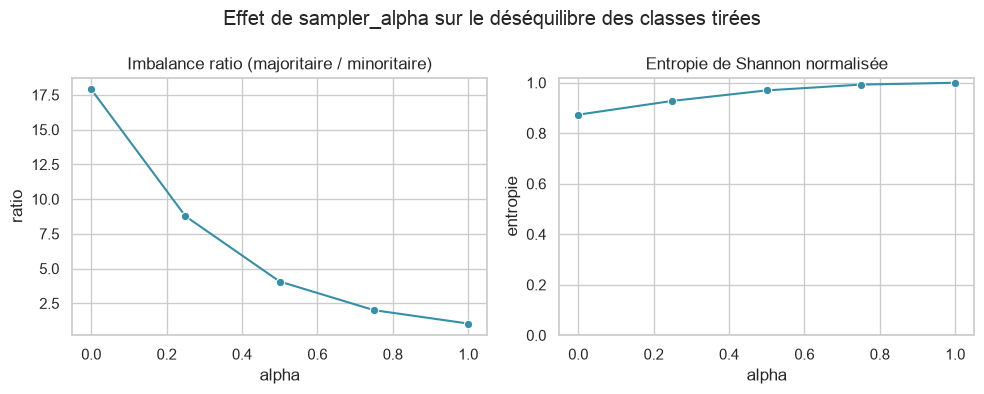

In [ ]:
# Deux échelles différentes (ratio vs entropie) : deux panneaux plutôt qu'un double axe y.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.lineplot(data=summary_df, x="alpha", y="imbalance_ratio", marker="o", ax=axes[0], color=accent)
axes[0].set_title("Imbalance ratio (majoritaire / minoritaire)")
axes[0].set_ylabel("ratio")

sns.lineplot(data=summary_df, x="alpha", y="shannon_entropy", marker="o", ax=axes[1], color=accent)
axes[1].set_title("Entropie de Shannon normalisée")
axes[1].set_ylabel("entropie")
axes[1].set_ylim(0, 1.02)

fig.suptitle("Effet de sampler_alpha sur le déséquilibre des classes tirées")
fig.tight_layout()
plt.show()

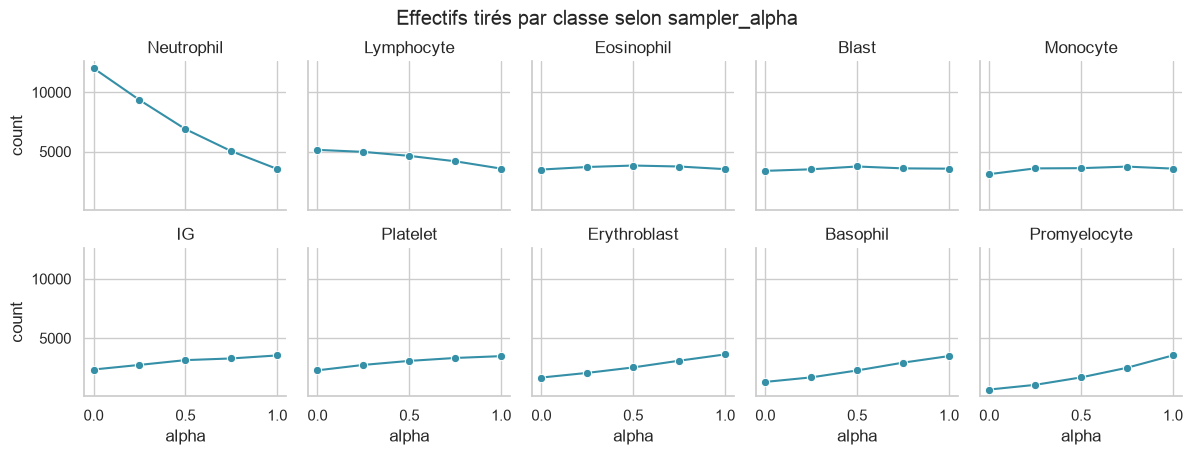

In [ ]:
# Petits multiples par classe (plutôt qu'une palette catégorielle à 10 couleurs) :
# l'identité de la classe est portée par le titre du panneau, la couleur reste
# constante. Même échelle y sur tous les panneaux pour voir la convergence des
# effectifs vers l'équilibre quand alpha -> 1.
class_order = (
    counts_df[counts_df["alpha"] == 0.0].sort_values("count", ascending=False)["class"].tolist()
)
counts_df["class"] = pd.Categorical(counts_df["class"], categories=class_order, ordered=True)

g = sns.relplot(
    data=counts_df,
    x="alpha",
    y="count",
    col="class",
    col_wrap=5,
    kind="line",
    marker="o",
    color=accent,
    height=2.2,
    aspect=1.1,
    facet_kws={"sharey": True},
)
g.set_titles("{col_name}")
g.fig.suptitle("Effectifs tirés par classe selon sampler_alpha", y=1.03)
plt.show()

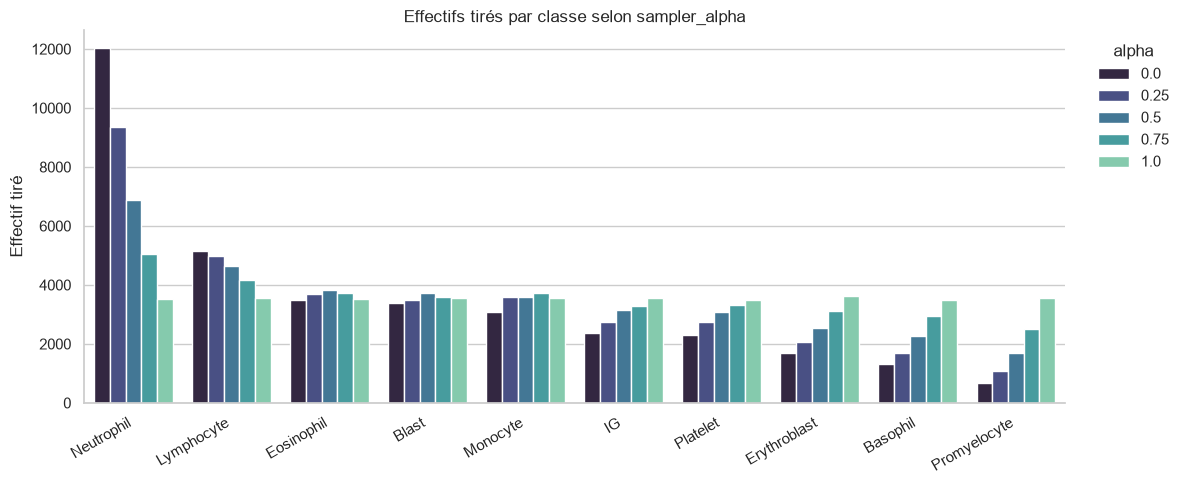

In [ ]:
# alpha est une variable ordonnée -> palette séquentielle (mako, cohérente avec
# les figures précédentes) plutôt que la palette catégorielle par défaut ;
# figure élargie + labels x tournés pour que les 10 classes restent lisibles ;
# légende sortie du graphique pour ne pas recouvrir les barres.
palette = sns.color_palette("mako", n_colors=counts_df["alpha"].nunique())

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(
    data=counts_df, x="class", y="count", hue="alpha", palette=palette, errorbar=None, ax=ax
)
ax.set_title("Effectifs tirés par classe selon sampler_alpha")
ax.set_xlabel(None)
ax.set_ylabel("Effectif tiré")
ax.tick_params(axis="x", rotation=30)
for label in ax.get_xticklabels():
    label.set_ha("right")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1), title="alpha", frameon=False)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

In [ ]:
display(counts_df[counts_df["class"].isin(["Promyelocyte", "Neutrophil"])])

,alpha,class,count
7,0.00,Neutrophil,12027
9,0.00,Promyelocyte,672
17,0.25,Neutrophil,9348
19,0.25,Promyelocyte,1066
27,0.50,Neutrophil,6894
29,0.50,Promyelocyte,1695
37,0.75,Neutrophil,5032
39,0.75,Promyelocyte,2506
47,1.00,Neutrophil,3532
49,1.00,Promyelocyte,3550


In [66]:
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", None)

leaderboard_path = Path.cwd().parent / "results" / "leaderboard.csv"
df = pd.read_csv(leaderboard_path, parse_dates=["timestamp"])
df["val_f1_recall"] = df.apply(
    lambda row: (row.val_f1_macro + row.val_min_critical_recall) / 2.0, axis=1
)

In [39]:
run_name = "grid_citicality_loss_2"

cols = sorted([c for c in df.columns if c.startswith(("loss", "val", "train"))])
df[df.name == run_name][cols].sort_values(by="val_f1_macro", ascending=False)


,loss.beta,loss.cost_matrix,loss.extra_weight.Blast,loss.extra_weight.Erythroblast,loss.extra_weight.IG,loss.extra_weight.Promyelocyte,loss.gamma,loss.label_smoothing,loss.lambda_cost,loss.name,train.batch_size,train.cross_val_folds,train.device,train.early_stopping_patience,train.grad_clip_norm,train.nb_epoch,train.num_workers,train.sampler,train.sampler_alpha,train.val_size,train.validation,val_acc,val_critical_screening_ap,val_f1_macro,val_f1_recall,val_grouped_critical_recall,val_loss,val_mcc,val_min_critical_recall,val_top3_acc,val_top3_f1
1057,0.9999,NaN,NaN,NaN,NaN,NaN,3.0,0.0,0.0,clinical,64,3,auto,10,1.0,10,10.0,none,1.0,0.15,holdout,NaN,NaN,0.919856,0.938232,NaN,0.043388,0.880115,0.956608,NaN,NaN
1053,0.9999,NaN,NaN,NaN,NaN,NaN,2.0,0.0,0.0,clinical,64,3,auto,10,1.0,10,10.0,none,1.0,0.15,holdout,NaN,NaN,0.919073,0.938826,NaN,0.069841,0.879247,0.958580,NaN,NaN
1033,0.9990,NaN,NaN,NaN,NaN,NaN,1.0,0.0,0.0,clinical,64,3,auto,10,1.0,10,10.0,none,1.0,0.15,holdout,NaN,NaN,0.917500,0.928178,NaN,0.124415,0.877809,0.938856,NaN,NaN
1029,0.9990,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,clinical,64,3,auto,10,1.0,10,10.0,none,1.0,0.15,holdout,NaN,NaN,0.917490,0.935076,NaN,0.221634,0.876626,0.952663,NaN,NaN
1021,0.9900,NaN,NaN,NaN,NaN,NaN,2.0,0.0,0.0,clinical,64,3,auto,10,1.0,10,10.0,none,1.0,0.15,holdout,NaN,NaN,0.916683,0.934673,NaN,0.077208,0.876444,0.952663,NaN,NaN
1014,0.9900,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.5,clinical,64,3,auto,10,1.0,10,10.0,none,1.0,0.15,holdout,NaN,NaN,0.916651,0.919864,NaN,0.397331,0.875415,0.923077,NaN,NaN
1030,0.9990,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.5,clinical,64,3,auto,10,1.0,10,10.0,none,1.0,0.15,holdout,NaN,NaN,0.915856,0.920452,NaN,0.389789,0.874645,0.925049,NaN,NaN
1035,0.9990,NaN,NaN,NaN,NaN,NaN,1.0,0.0,1.0,clinical,64,3,auto,10,1.0,10,10.0,none,1.0,0.15,holdout,NaN,NaN,0.915430,0.929116,NaN,0.411680,0.874204,0.942801,NaN,NaN
1041,0.9990,NaN,NaN,NaN,NaN,NaN,3.0,0.0,0.0,clinical,64,3,auto,10,1.0,10,10.0,none,1.0,0.15,holdout,NaN,NaN,0.914288,0.937420,NaN,0.050731,0.872362,0.960552,NaN,NaN
1045,0.9999,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,clinical,64,3,auto,10,1.0,10,10.0,none,1.0,0.15,holdout,NaN,NaN,0.913766,0.933214,NaN,0.241818,0.872923,0.952663,NaN,NaN


In [40]:
run_name = "grid_cost_matrix_1"
pd.set_option("display.max_colwidth", None)
cols = [
    "loss.cost_matrix",
    "loss.lambda_cost",
    "loss.beta",
    "loss.gamma",
    "train.sampler",
    "train.sampler_alpha",
    "val_f1_macro",
    "val_min_critical_recall",
    "val_f1_recall",
    "val_mcc",
]

df_test = (
    df[df.name == run_name][cols]
    .sort_values(by="val_f1_recall", ascending=False)
    .reset_index(drop=True)
)
df_test.head(25)


,loss.cost_matrix,loss.lambda_cost,loss.beta,loss.gamma,train.sampler,train.sampler_alpha,val_f1_macro,val_min_critical_recall,val_f1_recall,val_mcc
0,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 1.0]]",1.0,0.0000,0.0,none,1.0,0.921016,0.968442,0.944729,0.882389
1,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 1.0]]",1.0,0.0000,0.0,none,1.0,0.913733,0.974359,0.944046,0.872545
2,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 0.0]]",1.0,0.0000,0.0,none,1.0,0.914493,0.970414,0.942454,0.873067
3,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [8.0, 2.0, 0.0]]",1.0,0.0000,0.0,none,1.0,0.913275,0.970414,0.941845,0.871176
4,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 0.0]]",1.0,0.0000,0.0,none,1.0,0.915973,0.966469,0.941221,0.875057
5,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 0.0]]",1.0,0.9999,0.0,weight,1.0,0.908085,0.970414,0.939249,0.863526
6,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [6.0, 2.0, 1.0]]",1.0,0.0000,0.0,none,1.0,0.905782,0.972387,0.939084,0.860649
7,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 1.0]]",0.5,0.0000,0.0,none,1.0,0.907009,0.970414,0.938712,0.862032
8,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 0.0]]",3.0,0.0000,0.0,none,1.0,0.892344,0.984221,0.938283,0.843283
9,"[[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 0.0]]",1.0,0.0000,0.0,none,1.0,0.901288,0.974359,0.937824,0.854666


In [41]:
df[df.name == run_name][cols].sort_values(by="val_f1_macro", ascending=False).iloc[0][
    "loss.cost_matrix"
]


'[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 1.0]]'

In [42]:
df[df.name == run_name].groupby(["loss.cost_matrix", "loss.lambda_cost"])[
    ["val_f1_macro", "val_f1_recall", "val_min_critical_recall", "val_mcc"]
].agg(["mean", "std"])

val_f1_macro  \
                                                                              mean   
loss.cost_matrix                                     loss.lambda_cost                
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [10.0, 2.0, 0.0]] 1.0                  0.895034   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [10.0, 2.0, 1.0]] 1.0                  0.892994   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 0.0]]  0.5                  0.906160   
                                                     1.0                  0.904336   
                                                     1.5                  0.894151   
                                                     2.0                  0.869673   
                                                     3.0                  0.892344   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 1.0]]  1.0                  0.907005   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 0.0]]  1.0                  0.901759   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 1.0]]  0.5                  0.907009   
                                                     1.0                  0.911851   
                                                     1.5                  0.910382   
                                                     2.0                  0.908783   
                                                     3.0                  0.892976   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [6.0, 2.0, 0.0]]  1.0                  0.899619   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [6.0, 2.0, 1.0]]  1.0                  0.905782   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [8.0, 2.0, 0.0]]  1.0                  0.913275   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [8.0, 2.0, 1.0]]  1.0                  0.902722   
[[0.0, 0.5, 1.0], [3.0, 0.0, 1.0], [4.0, 2.0, 1.0]]  1.0                  0.905742   
[[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 0.0]] 1.0                  0.901288   
[[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 1.0]] 1.0                  0.899074   

                                                                                 \
                                                                            std   
loss.cost_matrix                                     loss.lambda_cost             
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [10.0, 2.0, 0.0]] 1.0                    NaN   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [10.0, 2.0, 1.0]] 1.0                    NaN   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 0.0]]  0.5                    NaN   
                                                     1.0               0.010068   
                                                     1.5                    NaN   
                                                     2.0                    NaN   
                                                     3.0                    NaN   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 1.0]]  1.0               0.007699   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 0.0]]  1.0               0.010138   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 1.0]]  0.5                    NaN   
                                                     1.0               0.007129   
                                                     1.5                    NaN   
                                                     2.0                    NaN   
                                                     3.0                    NaN   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [6.0, 2.0, 0.0]]  1.0                    NaN   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [6.0, 2.0, 1.0]]  1.0                    NaN   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [8.0, 2.0, 0.0]]  1.0                    NaN   
[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [8.0, 2.0, 1.0]]  1.0                    NaN   
[[0.0, 0.5, 1.0], [3.0, 0.0, 1.0], [4.0, 2.0, 1.0]]  1.0                    NaN   
[[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 0.0]] 1.0                    NaN   
[[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 1.0]] 1.0                    NaN   

            

In [45]:
run_name = "grid_cost_matrix_type_1"
pd.set_option("display.max_colwidth", None)
param_cols = [
    "loss.cost_matrix",
    "loss.lambda_cost",
    "loss.beta",
    "loss.gamma",
    "train.sampler",
    "train.sampler_alpha",
]
metric_cols = [
    "val_f1_macro",
    "val_min_critical_recall",
    "val_f1_recall",
    "val_mcc",
]

df_test = (
    df[df.name == run_name][param_cols + metric_cols]
    .sort_values(by="val_f1_recall", ascending=False)
    .reset_index(drop=True)
)
df_test.head(25)

,loss.cost_matrix,loss.lambda_cost,loss.beta,loss.gamma,train.sampler,train.sampler_alpha,val_f1_macro,val_min_critical_recall,val_f1_recall,val_mcc
0,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 1.0]]",1.0,0.0,0.0,weight,0.5,0.842869,0.875000,0.858934,0.825828
1,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [10.0, 2.0, 1.0]]",1.0,0.0,0.0,weight,0.5,0.848422,0.852273,0.850347,0.834203
2,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 0.0]]",1.0,0.0,0.0,weight,0.5,0.845808,0.829545,0.837677,0.834964
3,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [10.0, 2.0, 0.0]]",1.0,0.0,0.0,weight,0.5,0.831111,0.840909,0.836010,0.815019
4,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [8.0, 2.0, 1.0]]",1.0,0.0,0.0,weight,0.5,0.847114,0.820755,0.833934,0.842020
5,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 1.0]]",1.0,0.0,0.0,weight,0.0,0.859677,0.806818,0.833247,0.856237
6,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [6.0, 2.0, 0.0]]",1.0,0.0,0.0,weight,0.5,0.824199,0.840909,0.832554,0.807185
7,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [8.0, 2.0, 1.0]]",1.0,0.0,0.0,weight,0.5,0.826306,0.829545,0.827926,0.815640
8,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 1.0]]",1.0,0.0,0.0,weight,0.5,0.832647,0.818182,0.825414,0.816448
9,"[[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 0.0]]",1.0,0.0,0.0,weight,0.5,0.818177,0.829545,0.823861,0.805867


In [51]:
df[df.name == run_name].groupby(param_cols)[metric_cols].agg(
    ["mean", "std", "size"]
).reset_index().sort_values(("val_f1_recall", "mean"), ascending=False)

loss.cost_matrix loss.lambda_cost  \
                                                                            
21  [[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 0.0]]              1.0   
14   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [6.0, 2.0, 1.0]]              1.0   
22  [[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 1.0]]              1.0   
17   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [8.0, 2.0, 0.0]]              1.0   
7    [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 1.0]]              1.0   
0   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [10.0, 2.0, 0.0]]              1.0   
11   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 1.0]]              1.0   
19   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [8.0, 2.0, 1.0]]              1.0   
10   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 1.0]]              1.0   
13   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [6.0, 2.0, 0.0]]              1.0   
15   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [6.0, 2.0, 1.0]]              1.0   
2   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [10.0, 2.0, 1.0]]              1.0   
9    [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 0.0]]              1.0   
3   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [10.0, 2.0, 1.0]]              1.0   
23  [[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 1.0]]              1.0   
20  [[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 0.0]]              1.0   
8    [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 0.0]]              1.0   
1   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [10.0, 2.0, 0.0]]              1.0   
5    [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 0.0]]              1.0   
16   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [8.0, 2.0, 0.0]]              1.0   
12   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [6.0, 2.0, 0.0]]              1.0   
6    [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 1.0]]              1.0   
4    [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 0.0]]              1.0   
18   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [8.0, 2.0, 1.0]]              1.0   

   loss.beta loss.gamma train.sampler train.sampler_alpha val_f1_macro  \
                                                                  mean   
21       0.0        0.0        weight                 0.5     0.832690   
14       0.0        0.0        weight                 0.0     0.851029   
22       0.0        0.0        weight                 0.0     0.847834   
17       0.0        0.0        weight                 0.5     0.825186   
7        0.0        0.0        weight                 0.5     0.833868   
0        0.0        0.0        weight                 0.0     0.824210   
11       0.0        0.0        weight                 0.5     0.837135   
19       0.0        0.0        weight                 0.5     0.837240   
10       0.0        0.0        weight                 0.0     0.837961   
13       0.0        0.0        weight                 0.5     0.826295   
15       0.0        0.0        weight                 0.5     0.834566   
2        0.0        0.0        weight                 0.0     0.834744   
9        0.0        0.0        weight                 0.5     0.835960   
3        0.0        0.0        weight                 0.5     0.833664   
23       0.0        0.0        weight                 0.5     0.828743   
20       0.0        0.0        weight                 0.0     0.792154   
8        0.0        0.0        weight                 0.0     0.853826   
1        0.0        0.0        weight                 0.5     0.827120   
5        0.0        0.0        weight                 0.5     0.823663   
16       0.0        0.0        weight                 0.0     0.830057   
12       0.0        0.0        weight                 0.0     0.843887   
6        0.0        0.0        weight                 0.0     0.815808   
4        0.0        0.0        weight                 0.0     0.814265   
18       0.0        0.0        weight                 0.0     0.823762   

                  val_min_critical_recall                val_f1_recall  \
         std size                    m

In [60]:
run_name = "grid_search_imbalance_3"
param_cols = ["loss.beta", "loss.gamma", "train.sampler_alpha", "loss.cost_matrix"]
df[df.name == run_name].groupby(param_cols, dropna=False)[metric_cols].agg(
    ["mean", "std", "size"]
).reset_index().sort_values(("val_f1_recall", "mean"), ascending=False)


loss.beta loss.gamma train.sampler_alpha  \
                                              
18    0.9990        0.0                 1.0   
41    0.9999        1.0                 1.0   
19    0.9990        0.0                 1.0   
38    0.9999        1.0                 1.0   
20    0.9990        0.0                 1.0   
16    0.9990        0.0                 1.0   
40    0.9999        1.0                 1.0   
39    0.9999        1.0                 1.0   
42    0.9999        1.0                 1.0   
43    0.9999        1.0                 1.0   
30    0.9990        2.0                 0.0   
17    0.9990        0.0                 1.0   
12    0.9990        0.0                 0.5   
14    0.9990        0.0                 0.5   
29    0.9990        2.0                 0.0   
10    0.9990        0.0                 0.5   
21    0.9990        0.0                 1.0   
15    0.9990        0.0                 0.5   
35    0.9999        0.0                 1.0   
45    0.9999        2.0                 0.5   
24    0.9990        1.0                 1.0   
32    0.9990        2.0                 1.0   
22    0.9990        1.0                 0.0   
11    0.9990        0.0                 0.5   
13    0.9990        0.0                 0.5   
37    0.9999        1.0                 0.5   
44    0.9999        2.0                 0.0   
34    0.9999        0.0                 0.5   
46    0.9999        2.0                 1.0   
33    0.9999        0.0                 0.0   
5     0.0000        1.0                 1.0   
8     0.0000        2.0                 1.0   
31    0.9990        2.0                 0.5   
23    0.9990        1.0                 0.5   
25    0.9990        2.0                 0.0   
2     0.0000        0.0                 1.0   
27    0.9990        2.0                 0.0   
36    0.9999        1.0                 0.0   
4     0.0000        1.0                 0.5   
26    0.9990        2.0                 0.0   
7     0.0000        2.0                 0.5   
28    0.9990        2.0                 0.0   
0     0.0000        0.0                 0.0   
1     0.0000        0.0                 0.5   
9     0.9990        0.0                 0.0   
6     0.0000        2.0                 0.0   
3     0.0000        1.0                 0.0   

                                        loss.cost_matrix val_f1_macro  \
                                                                 mean   
18   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 0.0]]     0.871159   
41   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [6.0, 3.0, 0.0]]     0.857732   
19   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [6.0, 3.0, 0.0]]     0.856904   
38   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 0.0]]     0.855433   
20  [[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 0.0]]     0.860946   
16   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 0.0]]     0.854247   
40   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 0.0]]     0.856127   
39   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 1.0]]     0.867810   
42  [[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 0.0]]     0.855346   
43                                                   NaN     0.867359   
30                                                   NaN     0.864720   
17   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 1.0]]     0.874087   
12   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 3.0, 0.0]]     0.865085   
14  [[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 0.0]]     0.862732   
29  [[0.0, 0.5, 1.0], [4.0, 0.0, 1.0], [10.0, 3.0, 0.0]]     0.853271   
10   [[0.0, 0.5, 1.0], [2.0, 0.0, 1.0], [4.0, 2.0, 0.0]]     0.867607   
21                                                   NaN     0.870835   
15                                                   NaN     0.865838   
35                                                   NaN     0.867234   
45                                                   NaN     0.868438   
24                                                   NaN     0.867668   
32                  

In [59]:
df[df.name == run_name]

,run_dir,name,timestamp,task,seed,duration_s,status,error,data.datasets,data.n_images,data.test_size,data.stratify,transform.img_size,transform.reinhard,transform.reinhard_samples,transform.clahe,transform.clahe_clip_limit,transform.clahe_grid_size,transform.jpeg,transform.jpeg_quality,transform.p_rotation,transform.p_brightness,transform.p_contrast,transform.brightness_delta,transform.contrast_delta,model.name,loss.name,loss.beta,loss.gamma,loss.lambda_cost,optim.name,optim.lr,optim.weight_decay,scheduler.name,scheduler.patience,scheduler.lr_min,scheduler.step_gamma,train.nb_epoch,train.batch_size,train.validation,train.val_size,train.cross_val_folds,train.early_stopping_patience,train.device,output.root,output.save_checkpoint,output.save_figures,test_loss,test_f1_macro,test_mcc,min_critical_recall,val_f1_macro,transform.p_flip,test_acc,grid.max_combinations,train.sampler,verbose,train.sampler_alpha,train.num_workers,test_top3_acc,test_top3_f1,train.grad_clip_norm,val_min_critical_recall,val_loss,val_mcc,val_top3_acc,val_top3_f1,val_acc,transform.p_blur,transform.blur_kernel_size,transform.blur_sigma_min,transform.blur_sigma_max,loss.extra_weight.Blast,loss.extra_weight.Promyelocyte,loss.extra_weight.IG,loss.extra_weight.Erythroblast,model.architecture,transform.norm_stats,model.transfer,loss.label_smoothing,loss.cost_matrix,val_critical_screening_ap,val_grouped_critical_recall,val_f1_recall
1200,results/runs/51efb22f,grid_search_imbalance_3,2026-09-12 00:27:08,type,0,226.2,ok,NaN,"['barcelona', 'munich']",15000,0.15,type_dataset,"[224, 224]",True,500,True,2.0,8,True,60,0.5,0.5,0.5,0.25,0.15,baseline,clinical,0.0000,0.0,0.0,adam,0.001,0.0,none,3,0.0,0.1,10,64,holdout,0.15,3,0,auto,results,False,False,NaN,NaN,NaN,NaN,0.888578,0.5,NaN,200.0,weight,True,0.0,8.0,NaN,NaN,1.0,0.818182,0.334294,0.888068,0.986140,0.985982,NaN,0.0,5.0,0.1,2.0,NaN,NaN,NaN,NaN,NaN,dataset,NaN,0.0,NaN,0.914303,0.902062,0.853380
1201,results/runs/ba75dd2e,grid_search_imbalance_3,2026-09-12 00:30:55,type,0,227.5,ok,NaN,"['barcelona', 'munich']",15000,0.15,type_dataset,"[224, 224]",True,500,True,2.0,8,True,60,0.5,0.5,0.5,0.25,0.15,baseline,clinical,0.0000,0.0,0.0,adam,0.001,0.0,none,3,0.0,0.1,10,64,holdout,0.15,3,0,auto,results,False,False,NaN,NaN,NaN,NaN,0.857913,0.5,NaN,200.0,weight,True,0.5,8.0,NaN,NaN,1.0,0.704545,0.373093,0.857202,0.985447,0.984402,NaN,0.0,5.0,0.1,2.0,NaN,NaN,NaN,NaN,NaN,dataset,NaN,0.0,NaN,0.904161,0.855670,0.781229
1202,results/runs/bc0ac6cf,grid_search_imbalance_3,2026-09-12 00:34:54,type,0,239.0,ok,NaN,"['barcelona', 'munich']",15000,0.15,type_dataset,"[224, 224]",True,500,True,2.0,8,True,60,0.5,0.5,0.5,0.25,0.15,baseline,clinical,0.0000,0.0,0.0,adam,0.001,0.0,none,3,0.0,0.1,10,64,holdout,0.15,3,0,auto,results,False,False,NaN,NaN,NaN,NaN,0.851654,0.5,NaN,200.0,weight,True,1.0,8.0,NaN,NaN,1.0,0.772727,0.425655,0.847407,0.984061,0.982597,NaN,0.0,5.0,0.1,2.0,NaN,NaN,NaN,NaN,NaN,dataset,NaN,0.0,NaN,0.866884,0.917526,0.812190
1203,results/runs/8b0060f0,grid_search_imbalance_3,2026-09-12 00:39:17,type,1,263.0,ok,NaN,"['barcelona', 'munich']",15000,0.15,type_dataset,"[224, 224]",True,500,True,2.0,8,True,60,0.5,0.5,0.5,0.25,0.15,baseline,clinical,0.0000,0.0,0.0,adam,0.001,0.0,none,3,0.0,0.1,10,64,holdout,0.15,3,0,auto,results,False,False,NaN,NaN,NaN,NaN,0.843348,0.5,NaN,200.0,weight,True,0.0,8.0,NaN,NaN,1.0,0.704545,0.431786,0.837308,0.975052,0.973053,NaN,0.0,5.0,0.1,2.0,NaN,NaN,NaN,NaN,NaN,dataset,NaN,0.0,NaN,0.923879,0.902062,0.773947
1204,results/runs/4e04bbcb,grid_search_imbalance_3,2026-09-12 00:43:21,type,1,244.1,ok,NaN,"['barcelona', 'munich']",15000,0.15,type_dataset,"[224, 224]",True,500,True,2.0,8,True,60,0.5,0.5,0.5,0.25,0.15,baseline,clinical,0.0000,0.0,0.0,adam,0.001,0.0,none,3,0.0,0.1,10,64,holdout,0.15,3,0,auto,results,False,False,NaN,NaN,NaN,NaN,0.879161,0.5,NaN,200.0,weight,True,0.5,8.0,NaN,NaN,1.0,0.784091,0.332447,0.867214,0.988912,0.988770,NaN,0.0,5.0,0.1,2.0,NaN,NaN,NaN,NaN,NaN,dataset,NaN,0.0,NaN,0.967800,0.891753,0.8

In [67]:
cols = ["run_dir", "name", "task", "optim.name", "scheduler.name"] + [
    c for c in df.columns if c.startswith("test_")
]
df[df.name.str.startswith("run_final")][cols]

,run_dir,name,task,optim.name,scheduler.name,test_loss,test_f1_macro,test_mcc,test_acc,test_top3_acc,test_top3_f1,test_critical_screening_ap,test_grouped_critical_recall
1341,results/runs/dabfc74c,run_final_type_baseline,type,adam,none,0.267084,0.911296,0.929360,0.924906,0.994734,0.993504,0.954810,0.954698
1342,results/runs/58a76587,run_final_type_baseline_2,type,adam,plateau,0.245751,0.916049,0.931530,0.927950,0.995110,0.994490,0.963886,0.949664
1343,results/runs/6ff301ef,run_final_type_baseline_3,type,adamw,plateau,0.251159,0.911054,0.928377,0.923679,0.995110,0.993452,0.960953,0.953020
1344,results/runs/a2bfd293,run_final_criticality_baseline_1,criticality,adam,plateau,0.182521,0.928684,0.903154,0.932850,NaN,NaN,NaN,NaN
